# Упражнение: признаки изображений
Мы уже видели, что линейный классификатор, обученный на пикселях входного изображения, даёт вполне приемлемое качество в задаче классификации изображений. В этом упражнении мы покажем, что качество классификации можно повысить, если обучать линейные классификаторы не на исходных пикселях, а на признаках, вычисленных по этим пикселям.

Всю работу в этом упражнении вы выполняете прямо в этом ноутбуке.

In [1]:
# Настройка окружения (запустите эту ячейку первой).
# Откройте ноутбук из папки python/ задания, например: uv run jupyter lab
# При первом запуске скачается CIFAR-10 (~170 МБ): с сервера курса, а если он
# недоступен, с официального сайта. Источник можно задать явно переменной
# окружения DLCV_DATASET_SOURCE=racoon или official перед запуском Jupyter.
import os
import sys

if not os.path.isdir('dlcv'):
    raise FileNotFoundError(
        'В текущей папке нет пакета dlcv. Откройте ноутбук из папки python/ задания.')
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

from dlcv.data_utils import ensure_cifar10
ensure_cifar10()
print('Рабочая папка:', os.getcwd())
import numpy as np
np.random.seed(231)


Рабочая папка: C:\Users\yar04\OneDrive\Документы\ChatGPT\MISIS\deep-learning\assignment1


In [2]:
import random
import numpy as np
from dlcv.data_utils import load_CIFAR10
import matplotlib.pyplot as plt


%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0) # размер графиков по умолчанию
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

# автоматическая перезагрузка внешних модулей
# см. http://stackoverflow.com/questions/1907993/autoreload-of-modules-in-ipython
%load_ext autoreload
%autoreload 2

## Загрузка данных
Как и в предыдущих упражнениях, загрузим данные CIFAR-10 с диска.

In [3]:
from dlcv.features import color_histogram_hsv, hog_feature

def get_CIFAR10_data(num_training=49000, num_validation=1000, num_test=1000):
    # Загружаем исходные данные CIFAR-10
    cifar10_dir = 'dlcv/datasets/cifar-10-batches-py'

    # Удаляем старые переменные, чтобы данные не загружались в память повторно
    # (иначе памяти может не хватить)
    try:
       del X_train, y_train
       del X_test, y_test
       print('Ранее загруженные данные удалены.')
    except:
       pass

    X_train, y_train, X_test, y_test = load_CIFAR10(cifar10_dir)

    # Формируем подвыборки
    mask = list(range(num_training, num_training + num_validation))
    X_val = X_train[mask]
    y_val = y_train[mask]
    mask = list(range(num_training))
    X_train = X_train[mask]
    y_train = y_train[mask]
    mask = list(range(num_test))
    X_test = X_test[mask]
    y_test = y_test[mask]

    return X_train, y_train, X_val, y_val, X_test, y_test

X_train, y_train, X_val, y_val, X_test, y_test = get_CIFAR10_data()

## Извлечение признаков
Для каждого изображения вычислим гистограмму направленных градиентов (Histogram of Oriented Gradients, HOG), а также цветовую гистограмму по каналу тона (hue) в цветовом пространстве HSV. Итоговый вектор признаков изображения получим конкатенацией векторов признаков HOG и цветовой гистограммы.

Грубо говоря, HOG описывает текстуру изображения и не учитывает информацию о цвете, а цветовая гистограмма, наоборот, описывает цвет входного изображения и не учитывает текстуру. Поэтому можно ожидать, что вместе они сработают лучше, чем каждый по отдельности. Проверить это предположение самостоятельно — полезное упражнение для интересующихся.

Функции `hog_feature` и `color_histogram_hsv` принимают одно изображение и возвращают для него вектор признаков. Функция `extract_features` принимает набор изображений и список функций признаков, применяет каждую функцию к каждому изображению и сохраняет результаты в матрицу, каждая строка которой — конкатенация всех векторов признаков одного изображения.

In [4]:
from dlcv.features import *

# num_color_bins = 10 # Число бинов цветовой гистограммы
num_color_bins = 25 # Число бинов цветовой гистограммы
feature_fns = [hog_feature, lambda img: color_histogram_hsv(img, nbin=num_color_bins)]
X_train_feats = extract_features(X_train, feature_fns, verbose=True)
X_val_feats = extract_features(X_val, feature_fns)
X_test_feats = extract_features(X_test, feature_fns)

# Предобработка: вычитаем среднее значение каждого признака
mean_feat = np.mean(X_train_feats, axis=0, keepdims=True)
X_train_feats -= mean_feat
X_val_feats -= mean_feat
X_test_feats -= mean_feat

# Предобработка: делим на стандартное отклонение, чтобы все признаки
# имели примерно одинаковый масштаб.
std_feat = np.std(X_train_feats, axis=0, keepdims=True)
X_train_feats /= std_feat
X_val_feats /= std_feat
X_test_feats /= std_feat

# Предобработка: добавляем размерность для смещения (столбец из единиц)
X_train_feats = np.hstack([X_train_feats, np.ones((X_train_feats.shape[0], 1))])
X_val_feats = np.hstack([X_val_feats, np.ones((X_val_feats.shape[0], 1))])
X_test_feats = np.hstack([X_test_feats, np.ones((X_test_feats.shape[0], 1))])

Признаки извлечены для 1000 / 49000 изображений


Признаки извлечены для 2000 / 49000 изображений


Признаки извлечены для 3000 / 49000 изображений


Признаки извлечены для 4000 / 49000 изображений


Признаки извлечены для 5000 / 49000 изображений


...

Признаки извлечены для 45000 / 49000 изображений


Признаки извлечены для 46000 / 49000 изображений


Признаки извлечены для 47000 / 49000 изображений


Признаки извлечены для 48000 / 49000 изображений


Признаки извлечены для 49000 / 49000 изображений


## Обучение классификатора Softmax на признаках
С помощью кода Softmax, написанного ранее в этой лабораторной работе, обучите классификаторы Softmax на извлечённых выше признаках. Результат должен получиться лучше, чем при обучении непосредственно на исходных пикселях.

In [5]:
# Подберите скорость обучения и коэффициент регуляризации по валидационной выборке

from dlcv.classifiers.linear_classifier import Softmax

# Стартовые значения. Скорее всего, диапазоны придётся изменить: признаки
# нормированы, и подходящие значения могут отличаться от этих на порядки.
learning_rates = [0.05, 0.2]
regularization_strengths = [0.001, 0.01]

results = {}
best_val = -1
best_softmax = None

################################################################################
# Решение:                                                                        #
# Подберите скорость обучения и коэффициент регуляризации по валидационной     #
# выборке. Всё делается точно так же, как при подборе гиперпараметров для      #
# Softmax ранее; сохраните лучший обученный классификатор в best_softmax.      #
# При тщательной настройке модели точность (accuracy, доля правильных          #
# ответов) на валидационной выборке должна превысить 0.42.                     #
################################################################################


for lr in learning_rates:
    for reg in regularization_strengths:
        candidate = Softmax()
        candidate.train(X_train_feats, y_train, learning_rate=lr, reg=reg, num_iters=2500)
        train_acc = np.mean(candidate.predict(X_train_feats) == y_train)
        val_acc = np.mean(candidate.predict(X_val_feats) == y_val)
        results[(lr, reg)] = (train_acc, val_acc)
        if val_acc > best_val:
            best_val, best_softmax = val_acc, candidate
assert best_val > 0.42, best_val

# Выводим результаты.
for lr, reg in sorted(results):
    train_accuracy, val_accuracy = results[(lr, reg)]
    print('lr %e reg %e точность на обучении: %f точность на валидации: %f' % (
                lr, reg, train_accuracy, val_accuracy))

print('лучшая достигнутая точность на валидационной выборке: %f' % best_val)

lr 5.000000e-02 reg 1.000000e-03 точность на обучении: 0.524102 точность на валидации: 0.515000
lr 5.000000e-02 reg 1.000000e-02 точность на обучении: 0.520245 точность на валидации: 0.503000
lr 2.000000e-01 reg 1.000000e-03 точность на обучении: 0.515755 точность на валидации: 0.507000
lr 2.000000e-01 reg 1.000000e-02 точность на обучении: 0.510959 точность на валидации: 0.492000
лучшая достигнутая точность на валидационной выборке: 0.515000


In [6]:
# Оцените обученный Softmax на тестовой выборке: точность должна быть не ниже 0.42
y_test_pred = best_softmax.predict(X_test_feats)
test_accuracy = np.mean(y_test == y_test_pred)
print(test_accuracy)

0.506


In [7]:
# Сохраняем лучшую модель Softmax (файл появится в папке `dlcv/saved/`)
best_softmax.save("best_softmax_features.npy")

best_softmax_features.npy сохранён.


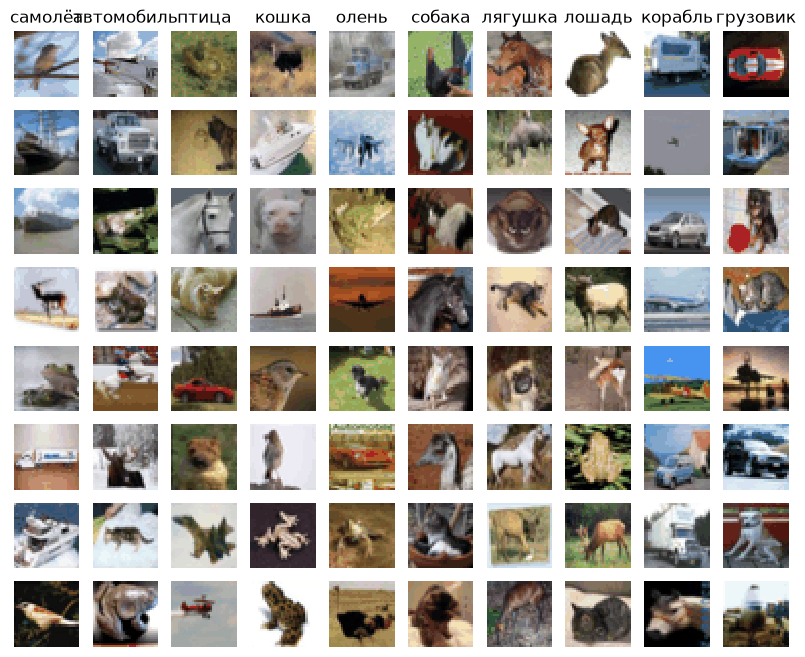

In [8]:
# Хороший способ интуитивно понять, как работает алгоритм, — посмотреть
# на ошибки, которые он совершает. Ниже показаны примеры изображений,
# которые текущая модель классифицировала неверно. В первом столбце —
# изображения, которым модель присвоила метку «самолёт», хотя на самом деле
# их истинная метка другая.

examples_per_class = 8
classes = ['самолёт', 'автомобиль', 'птица', 'кошка', 'олень', 'собака', 'лягушка', 'лошадь', 'корабль', 'грузовик']
for cls, cls_name in enumerate(classes):
    idxs = np.where((y_test != cls) & (y_test_pred == cls))[0]
    idxs = np.random.choice(idxs, min(examples_per_class, len(idxs)), replace=False)
    for i, idx in enumerate(idxs):
        plt.subplot(examples_per_class, len(classes), i * len(classes) + cls + 1)
        plt.imshow(X_test[idx].astype('uint8'))
        plt.axis('off')
        if i == 0:
            plt.title(cls_name)
plt.show()

### Вопрос 1
Опишите ошибки классификации, которые вы видите. Можно ли найти им разумное объяснение?

**Ваш ответ:** В столбце «самолёт» есть птицы и корабль: светлый фон и вытянутые контуры могут напоминать самолёт. В столбце «автомобиль» есть грузовики — похожи колёса и корпус. Цветовая гистограмма не хранит расположение цветов, а HOG описывает локальные границы, поэтому объекты разных классов с похожими фоном и контурами получают близкие признаки. Маленький объект может теряться на фоне; низкое разрешение CIFAR-10 также затрудняет различение.


## Нейронная сеть на признаках изображений
Ранее в этой лабораторной работе мы видели, что двухслойная нейронная сеть, обученная на исходных пикселях, классифицирует изображения лучше, чем линейные классификаторы на тех же пикселях. В этом ноутбуке мы убедились, что линейные классификаторы на признаках изображений превосходят линейные классификаторы на исходных пикселях.

Для полноты картины стоит также обучить нейронную сеть на признаках изображений. Этот подход должен превзойти все предыдущие: точность классификации на тестовой выборке выше 55% достигается без особого труда, а хорошо настроенная модель достигает 58–60%.

In [9]:
# Предобработка: удаляем размерность для смещения
# Обязательно запускайте эту ячейку только ОДИН раз
print(X_train_feats.shape)
X_train_feats = X_train_feats[:, :-1]
X_val_feats = X_val_feats[:, :-1]
X_test_feats = X_test_feats[:, :-1]

print(X_train_feats.shape)

(49000, 170)
(49000, 169)


In [10]:
from dlcv.classifiers.fc_net import TwoLayerNet
from dlcv.solver import Solver

input_dim = X_train_feats.shape[1]
hidden_dim = 500
num_classes = 10

data = {
    'X_train': X_train_feats,
    'y_train': y_train,
    'X_val': X_val_feats,
    'y_val': y_val,
    'X_test': X_test_feats,
    'y_test': y_test,
}

net = TwoLayerNet(input_dim, hidden_dim, num_classes)
best_net = None

################################################################################
# Решение: Обучите двухслойную нейронную сеть на признаках изображений.           #
# Имеет смысл подобрать различные гиперпараметры с помощью валидационной       #
# выборки, как в предыдущих разделах. Сохраните лучшую модель                  #
# в переменной best_net.                                                       #
################################################################################

best_val = -1
for lr, reg in [(1e-3, 1e-3), (5e-4, 1e-2)]:
    candidate = TwoLayerNet(input_dim, hidden_dim, num_classes, weight_scale=0.03, reg=reg)
    feature_solver = Solver(candidate, data, update_rule='adam',
                            optim_config={'learning_rate': lr}, lr_decay=0.95,
                            num_epochs=20, batch_size=200, print_every=1000)
    feature_solver.train()
    val = feature_solver.check_accuracy(data['X_val'], data['y_val'])
    print('lr, reg:', lr, reg, 'validation:', val)
    if val > best_val:
        best_val, best_net = val, candidate


(Итерация 1 / 4900) потери: 2.376251
(Эпоха 0 / 20) точность на обучении: 0.142000; на валидации: 0.139000


(Эпоха 1 / 20) точность на обучении: 0.576000; на валидации: 0.534000


(Эпоха 2 / 20) точность на обучении: 0.624000; на валидации: 0.563000


(Эпоха 3 / 20) точность на обучении: 0.633000; на валидации: 0.580000


(Эпоха 4 / 20) точность на обучении: 0.680000; на валидации: 0.607000
(Итерация 1001 / 4900) потери: 1.023799


...

(Итерация 4001 / 4900) потери: 1.309974


(Эпоха 17 / 20) точность на обучении: 0.570000; на валидации: 0.579000


(Эпоха 18 / 20) точность на обучении: 0.575000; на валидации: 0.573000


(Эпоха 19 / 20) точность на обучении: 0.628000; на валидации: 0.572000


(Эпоха 20 / 20) точность на обучении: 0.595000; на валидации: 0.570000
lr, reg: 0.0005 0.01 validation: 0.58


In [11]:
# Оцените лучший классификатор на основе нейронной сети на тестовой
# выборке. Точность должна получиться выше 55%, а при тщательной настройке
# можно добиться 58–60% и более.

y_test_pred = np.argmax(best_net.loss(data['X_test']), axis=1)
test_acc = (y_test_pred == data['y_test']).mean()
print(test_acc)

0.602


In [12]:
# Сохраняем лучшую модель (файл появится в папке `dlcv/saved/`)
best_net.save("best_two_layer_net_features.npy")

best_two_layer_net_features.npy сохранён.
